In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from PIL import ImageFile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from collections import Counter
import math
import copy
import os
from google.colab import drive

# Handle truncated images and large pixels
ImageFile.LOAD_TRUNCATED_IMAGES = True
ImageFile.MAX_IMAGE_PIXELS = None

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Mount Drive
drive.mount('/content/drive')

Using device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/dataset/dataset.zip'
extract_path = '/content/extracted_dataset'
os.makedirs(extract_path, exist_ok=True)

print(f"Unzipping dataset...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Update this path based on your folder structure after unzipping
dataset_root = '/content/extracted_dataset/dataset'

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])

train_dataset = datasets.ImageFolder(root=os.path.join(dataset_root, 'train'), transform=transform)
val_dataset = datasets.ImageFolder(root=os.path.join(dataset_root, 'val1'), transform=transform)
test_dataset = datasets.ImageFolder(root=os.path.join(dataset_root, 'test1'), transform=transform)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Dataset Loaded. Train size: {len(train_dataset)}")

Unzipping dataset...
Dataset Loaded. Train size: 6253


In [ ]:
def get_model():
    model = models.resnet18(pretrained=True)
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model.to(device)

def calculate_class_balance_score(dataset):
    labels = [label for _, label in dataset]
    if not labels: return 0.0
    counts = Counter(labels)
    total = len(labels)
    entropy = -sum((count/total) * math.log(count/total, 2) for count in counts.values() if count > 0)
    max_entropy = math.log(2, 2) # For 2 classes
    return entropy / max_entropy if max_entropy > 0 else 0.0

def evaluate_local_model_accuracy(model, dataloader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total if total > 0 else 0.0

def train_local(model, loader, epochs=1):
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    for _ in range(epochs):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    return model.state_dict()

def cbp_fedavg_aggregate_weights(global_model, client_weights_list, client_metrics_list, alpha=0.5, beta=0.5):
    client_agg_weights = []
    for m in client_metrics_list:
        score = m['n_k'] * (alpha * m['a_k'] + beta * m['b_k'])
        client_agg_weights.append(score)

    total_weight = sum(client_agg_weights)
    if total_weight == 0: return global_model.state_dict()

    normalized_weights = [w / total_weight for w in client_agg_weights]
    new_global_weights = copy.deepcopy(global_model.state_dict())

    for key in new_global_weights.keys():
        new_global_weights[key] = torch.zeros_like(new_global_weights[key], dtype=torch.float)

    for i, client_weights in enumerate(client_weights_list):
        for key in new_global_weights.keys():
            new_global_weights[key] += normalized_weights[i] * client_weights[key].float()

    for key in new_global_weights.keys():
        if global_model.state_dict()[key].dtype == torch.long:
            new_global_weights[key] = new_global_weights[key].round().long()

    return new_global_weights

def evaluate_model_full(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)

In [ ]:
all_experiment_results = {}
experiment_client_counts = [3, 5, 20]
num_rounds = 5

# Pre-group class indices for Non-IID splitting
class_indices = {0: [], 1: []}
for i, (_, label) in enumerate(train_dataset):
    class_indices[label].append(i)

for n_clients in experiment_client_counts:
    print(f"\n--- RUNNING EXPERIMENT: {n_clients} CLIENTS ---")

    # 1. Non-IID Partitioning
    c0_splits = np.array_split(class_indices[0], n_clients)
    c1_splits = np.array_split(class_indices[1], n_clients)
    client_loaders = []
    client_metadata = []
    for i in range(n_clients):
        indices = np.concatenate([c0_splits[i], c1_splits[i]])
        subset = Subset(train_dataset, indices)
        client_loaders.append(DataLoader(subset, batch_size=32, shuffle=True))
        client_metadata.append({'b_k': calculate_class_balance_score(subset), 'n_k': len(subset)})

    # 2. Training
    global_model = get_model()
    accuracies_per_round = []

    for r in range(num_rounds):
        client_weights = []
        client_metrics = []
        for i in range(n_clients):
            local_model = get_model()
            local_model.load_state_dict(global_model.state_dict())
            w = train_local(local_model, client_loaders[i])
            a_k = evaluate_local_model_accuracy(local_model, client_loaders[i])
            client_weights.append(w)
            client_metrics.append({'n_k': client_metadata[i]['n_k'], 'a_k': a_k, 'b_k': client_metadata[i]['b_k']})
            del local_model

        new_weights = cbp_fedavg_aggregate_weights(global_model, client_weights, client_metrics)
        global_model.load_state_dict(new_weights)

        v_labels, v_preds, _ = evaluate_model_full(global_model, val_loader)
        round_acc = np.mean(v_labels == v_preds)
        accuracies_per_round.append(round_acc)
        print(f"Round {r+1} Complete. Accuracy: {round_acc:.4f}")

    # 3. Save Model to Drive
    save_path = f'/content/drive/MyDrive/cbp_fedavg_{n_clients}_clients.pth'
    torch.save(global_model.state_dict(), save_path)
    print(f"Model saved to: {save_path}")

    all_experiment_results[n_clients] = {
        'accuracies': accuracies_per_round,
        'final_weights': copy.deepcopy(global_model.state_dict())
    }


--- RUNNING EXPERIMENT: 3 CLIENTS ---


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 174MB/s]


Round 1 Complete. Accuracy: 0.7762
Round 2 Complete. Accuracy: 0.8915
Round 3 Complete. Accuracy: 0.8974
Round 4 Complete. Accuracy: 0.9023
Round 5 Complete. Accuracy: 0.9082
Model saved to: /content/drive/MyDrive/cbp_fedavg_3_clients.pth

--- RUNNING EXPERIMENT: 5 CLIENTS ---
Round 1 Complete. Accuracy: 0.8425
Round 2 Complete. Accuracy: 0.8934
Round 3 Complete. Accuracy: 0.8957
Round 4 Complete. Accuracy: 0.9000
Round 5 Complete. Accuracy: 0.9180
Model saved to: /content/drive/MyDrive/cbp_fedavg_5_clients.pth

--- RUNNING EXPERIMENT: 20 CLIENTS ---
Round 1 Complete. Accuracy: 0.7899
Round 2 Complete. Accuracy: 0.8989
Round 3 Complete. Accuracy: 0.9098
Round 4 Complete. Accuracy: 0.9118
Round 5 Complete. Accuracy: 0.9121
Model saved to: /content/drive/MyDrive/cbp_fedavg_20_clients.pth


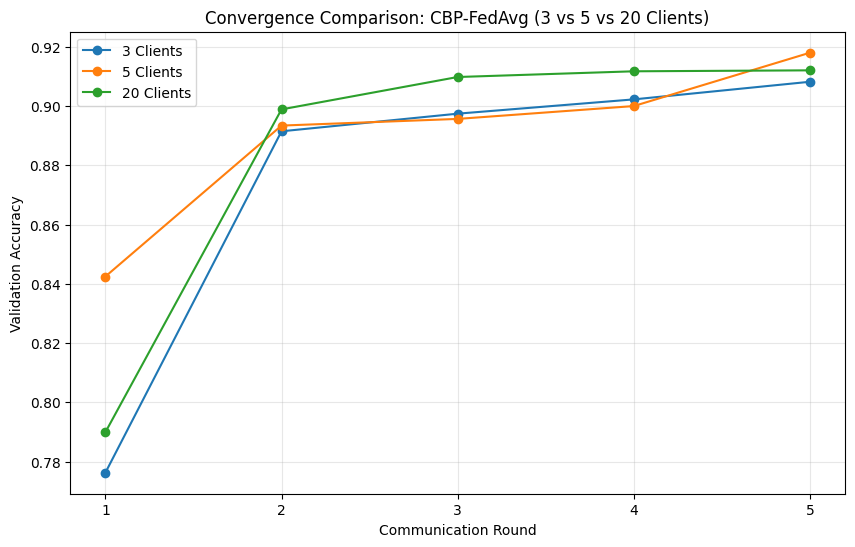


Clients    | Accuracy   | Precision  | Recall     | F1-Score  
--------------------------------------------------------------------------------
3          | 0.9040     | 0.9040     | 0.9040     | 0.9040    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


5          | 0.9046     | 0.9046     | 0.9046     | 0.9046    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


20         | 0.9054     | 0.9133     | 0.9054     | 0.9051    


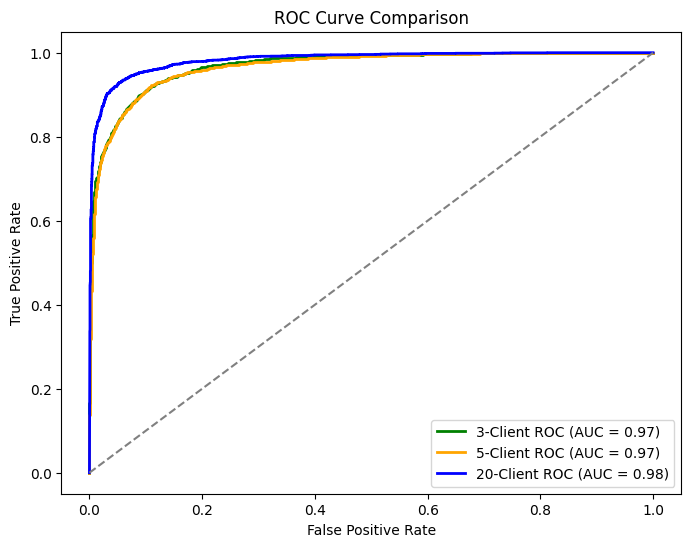

In [ ]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

# 1. Convergence Comparison Plot
plt.figure(figsize=(10, 6))
for n_clients, data in all_experiment_results.items():
    plt.plot(range(1, num_rounds + 1), data['accuracies'], marker='o', label=f'{n_clients} Clients')
plt.title("Convergence Comparison: CBP-FedAvg (3 vs 5 vs 20 Clients)")
plt.xlabel("Communication Round")
plt.ylabel("Validation Accuracy")
plt.xticks(range(1, num_rounds + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 2. Detailed Metrics Comparison Table
print(f"\n{'='*80}")
print(f"{'Clients':<10} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print(f"{'-'*80}")

final_metrics = {}

for n_clients in experiment_client_counts:
    # Load the specific model weights
    eval_model = get_model()
    eval_model.load_state_dict(all_experiment_results[n_clients]['final_weights'])

    # Get predictions
    y_true, y_pred, y_probs = evaluate_model_full(eval_model, test_loader)

    # Calculate Metrics
    acc = accuracy_score(y_true, y_pred)
    # Using 'weighted' average to account for potential Non-IID class imbalance in test set
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

    final_metrics[n_clients] = {'probs': y_probs, 'labels': y_true}

    print(f"{n_clients:<10} | {acc:<10.4f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f}")

print(f"{'='*80}")

# 3. Multi-Model ROC Curve Comparison
plt.figure(figsize=(8, 6))
colors = {3: 'green', 5: 'orange', 20: 'blue'}

for n_clients in experiment_client_counts:
    y_true = final_metrics[n_clients]['labels']
    y_probs = final_metrics[n_clients]['probs']

    fpr, tpr, _ = roc_curve(y_true, y_probs)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, color=colors[n_clients], lw=2,
             label=f'{n_clients}-Client ROC (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc="lower right")
plt.show()

Fednova logic

In [ ]:
def get_model():
    model = models.resnet18(pretrained=True)
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model.to(device)

def train_local_fednova(model, loader, epochs=1):
    model.train()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
    criterion = nn.CrossEntropyLoss()

    # Store initial weights to calculate the update (delta)
    initial_state = copy.deepcopy(model.state_dict())
    tau_i = 0 # Number of local steps

    for _ in range(epochs):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            tau_i += 1

    # Calculate normalized update: (initial_weights - final_weights) / local_steps
    normalized_update = {}
    final_state = model.state_dict()
    for key in initial_state.keys():
        normalized_update[key] = (initial_state[key].float() - final_state[key].float()) / tau_i

    return normalized_update, tau_i

def evaluate_model_full(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)

In [ ]:
fednova_results = {}
experiment_client_counts = [3, 5, 20]
num_rounds = 5

targets = np.array(train_dataset.targets)
class_indices = {0: np.where(targets == 0)[0], 1: np.where(targets == 1)[0]}

for n_clients in experiment_client_counts:
    print(f"\n--- RUNNING FEDNOVA: {n_clients} CLIENTS ---")
    c0_splits = np.array_split(class_indices[0], n_clients)
    c1_splits = np.array_split(class_indices[1], n_clients)

    client_loaders = [DataLoader(Subset(train_dataset, np.concatenate([c0_splits[i], c1_splits[i]])),
                                 batch_size=32, shuffle=True) for i in range(n_clients)]

    global_model = get_model()
    accuracies_per_round = []

    for r in range(num_rounds):
        local_updates = []
        tau_list = []
        n_i_list = [] # sample sizes

        for i in range(n_clients):
            local_model = get_model()
            local_model.load_state_dict(global_model.state_dict())

            update, tau = train_local_fednova(local_model, client_loaders[i])
            local_updates.append(update)
            tau_list.append(tau)
            n_i_list.append(len(client_loaders[i].dataset))
            del local_model

        # FedNova Aggregation
        total_n = sum(n_i_list)
        # weight = n_i / total_n
        # tau_eff = sum(weight * tau_i)
        tau_eff = sum([(n_i_list[i]/total_n) * tau_list[i] for i in range(n_clients)])

        new_global_state = global_model.state_dict()
        for key in new_global_state.keys():
            if new_global_state[key].dtype == torch.long: continue

            # Aggregated update = sum( weight_i * normalized_update_i ) * tau_eff
            weighted_update = torch.zeros_like(new_global_state[key], dtype=torch.float)
            for i in range(n_clients):
                weighted_update += (n_i_list[i] / total_n) * local_updates[i][key]

            new_global_state[key] -= tau_eff * weighted_update

        global_model.load_state_dict(new_global_state)
        v_labels, v_preds, _ = evaluate_model_full(global_model, val_loader)
        round_acc = accuracy_score(v_labels, v_preds)
        accuracies_per_round.append(round_acc)
        print(f"Round {r+1} Accuracy: {round_acc:.4f}")

    torch.save(global_model.state_dict(), f'/content/drive/MyDrive/fednova_{n_clients}_clients.pth')
    fednova_results[n_clients] = {'accuracies': accuracies_per_round, 'final_weights': copy.deepcopy(global_model.state_dict())}


--- RUNNING FEDNOVA: 3 CLIENTS ---


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 1 Accuracy: 0.9336


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 2 Accuracy: 0.9388


...

Round 3 Accuracy: 0.8614


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 4 Accuracy: 0.8896


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 5 Accuracy: 0.8897


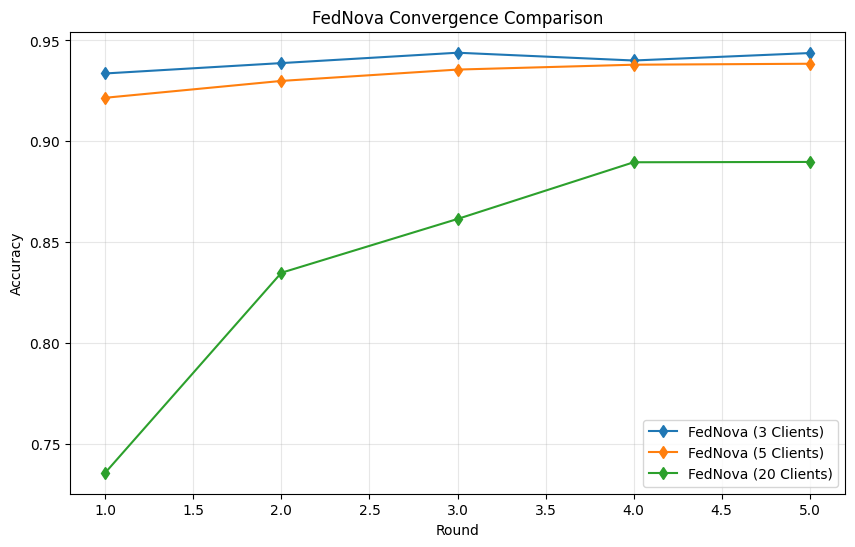


Clients    | Accuracy   | Precision  | Recall     | F1-Score  
---------------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


3          | 0.9459     | 0.9466     | 0.9459     | 0.9459    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


5          | 0.9365     | 0.9371     | 0.9365     | 0.9364    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


20         | 0.8949     | 0.8990     | 0.8949     | 0.8948    


In [ ]:
plt.figure(figsize=(10, 6))
for n_clients, data in fednova_results.items():
    plt.plot(range(1, num_rounds + 1), data['accuracies'], marker='d', label=f'FedNova ({n_clients} Clients)')
plt.title("FedNova Convergence Comparison")
plt.xlabel("Round")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"\n{'Clients':<10} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 75)

for n_clients in experiment_client_counts:
    eval_model = get_model()
    eval_model.load_state_dict(fednova_results[n_clients]['final_weights'])
    y_true, y_pred, _ = evaluate_model_full(eval_model, test_loader)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
    print(f"{n_clients:<10} | {acc:<10.4f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f}")

FedAvg Core Logic

In [ ]:
def get_model():
    model = models.resnet18(pretrained=True)
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model.to(device)

def train_local_fedavg(model, loader, epochs=1):
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    for _ in range(epochs):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
    return model.state_dict()

def aggregate_fedavg(local_weights_list, sample_counts):
    total_samples = sum(sample_counts)
    avg_weights = copy.deepcopy(local_weights_list[0])

    # Initialize weights to zero
    for key in avg_weights.keys():
        avg_weights[key] = torch.zeros_like(avg_weights[key], dtype=torch.float)

    # Weighted averaging
    for i, weights in enumerate(local_weights_list):
        contribution = sample_counts[i] / total_samples
        for key in avg_weights.keys():
            avg_weights[key] += weights[key].float() * contribution

    return avg_weights

def evaluate_model_full(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)

In [ ]:
fedavg_results = {}
experiment_client_counts = [3, 5, 20]
num_rounds = 5

targets = np.array(train_dataset.targets)
class_indices = {0: np.where(targets == 0)[0], 1: np.where(targets == 1)[0]}

for n_clients in experiment_client_counts:
    print(f"\n--- RUNNING FEDAVG: {n_clients} CLIENTS ---")
    c0_splits = np.array_split(class_indices[0], n_clients)
    c1_splits = np.array_split(class_indices[1], n_clients)

    client_loaders = [DataLoader(Subset(train_dataset, np.concatenate([c0_splits[i], c1_splits[i]])),
                                 batch_size=32, shuffle=True) for i in range(n_clients)]

    global_model = get_model()
    accuracies_per_round = []

    for r in range(num_rounds):
        local_weights = []
        sample_counts = []

        for i in range(n_clients):
            local_model = get_model()
            local_model.load_state_dict(global_model.state_dict())

            w = train_local_fedavg(local_model, client_loaders[i])
            local_weights.append(w)
            sample_counts.append(len(client_loaders[i].dataset))
            del local_model

        # Aggregate using sample-weighted averaging
        global_weights = aggregate_fedavg(local_weights, sample_counts)
        global_model.load_state_dict(global_weights)

        v_labels, v_preds, _ = evaluate_model_full(global_model, val_loader)
        round_acc = accuracy_score(v_labels, v_preds)
        accuracies_per_round.append(round_acc)
        print(f"Round {r+1} Accuracy: {round_acc:.4f}")

    torch.save(global_model.state_dict(), f'/content/drive/MyDrive/fedavg_{n_clients}_clients.pth')
    fedavg_results[n_clients] = {'accuracies': accuracies_per_round, 'final_weights': copy.deepcopy(global_model.state_dict())}


--- RUNNING FEDAVG: 3 CLIENTS ---


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 1 Accuracy: 0.8929


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 2 Accuracy: 0.9130


...

Round 3 Accuracy: 0.9314


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 4 Accuracy: 0.8497


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 5 Accuracy: 0.9302


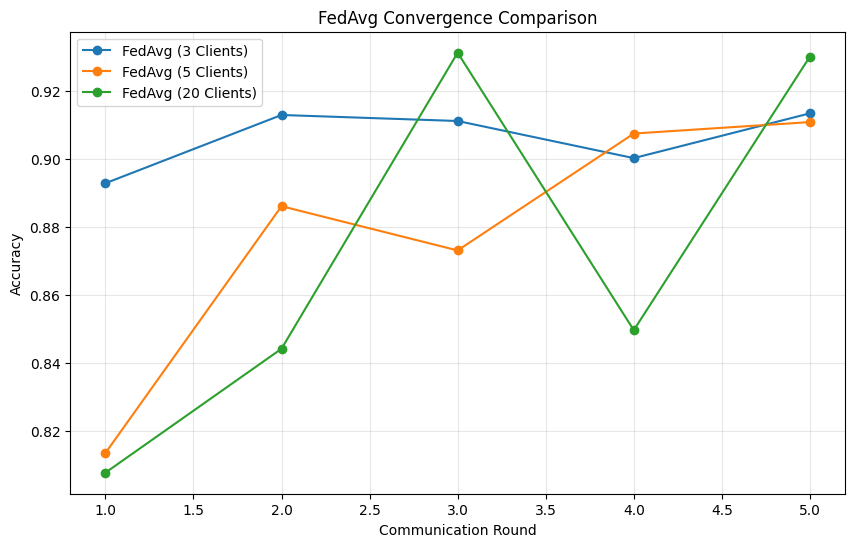


Clients    | Accuracy   | Precision  | Recall     | F1-Score  
---------------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


3          | 0.9028     | 0.9029     | 0.9028     | 0.9028    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


5          | 0.9067     | 0.9076     | 0.9067     | 0.9067    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


20         | 0.9299     | 0.9302     | 0.9299     | 0.9298    


In [ ]:
plt.figure(figsize=(10, 6))
for n_clients, data in fedavg_results.items():
    plt.plot(range(1, num_rounds + 1), data['accuracies'], marker='o', label=f'FedAvg ({n_clients} Clients)')
plt.title("FedAvg Convergence Comparison")
plt.xlabel("Communication Round")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"\n{'Clients':<10} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 75)

for n_clients in experiment_client_counts:
    eval_model = get_model()
    eval_model.load_state_dict(fedavg_results[n_clients]['final_weights'])
    y_true, y_pred, _ = evaluate_model_full(eval_model, test_loader)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
    print(f"{n_clients:<10} | {acc:<10.4f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f}")

frdprox

In [ ]:
def get_model():
    model = models.resnet18(pretrained=True)
    model.fc = nn.Linear(model.fc.in_features, 2) # Adult vs Non-Adult
    return model.to(device)

def train_local_fedprox(model, global_model, loader, mu=0.01, epochs=1):
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    # Extract global weights to calculate the distance for the proximal term
    global_weight_collector = list(global_model.parameters())

    for _ in range(epochs):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)

            # Standard Loss
            loss = criterion(outputs, labels)

            # FedProx Proximal Term: (mu/2) * ||w - w_t||^2
            proximal_term = 0.0
            for param, global_param in zip(model.parameters(), global_weight_collector):
                proximal_term += ((param - global_param)**2).sum()

            loss += (mu / 2) * proximal_term

            loss.backward()
            optimizer.step()
    return model.state_dict()

def average_weights(local_weights_list):
    avg_weights = copy.deepcopy(local_weights_list[0])
    for key in avg_weights.keys():
        for i in range(1, len(local_weights_list)):
            avg_weights[key] += local_weights_list[i][key]
        avg_weights[key] = avg_weights[key] / len(local_weights_list)
    return avg_weights

def evaluate_model_full(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs[:, 1].cpu().numpy())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)

In [ ]:
fedprox_results = {}
experiment_client_counts = [3, 5, 20]
num_rounds = 5
mu = 0.01

# Group indices by class for Non-IID distribution
targets = np.array(train_dataset.targets)
class_indices = {0: np.where(targets == 0)[0], 1: np.where(targets == 1)[0]}

for n_clients in experiment_client_counts:
    print(f"\n--- RUNNING FEDPROX: {n_clients} CLIENTS ---")

    # Non-IID Splitting
    c0_splits = np.array_split(class_indices[0], n_clients)
    c1_splits = np.array_split(class_indices[1], n_clients)

    client_loaders = []
    for i in range(n_clients):
        indices = np.concatenate([c0_splits[i], c1_splits[i]])
        client_loaders.append(DataLoader(Subset(train_dataset, indices), batch_size=32, shuffle=True))

    global_model = get_model()
    accuracies_per_round = []

    for r in range(num_rounds):
        local_weights = []
        for i in range(n_clients):
            local_model = get_model()
            local_model.load_state_dict(global_model.state_dict())

            w = train_local_fedprox(local_model, global_model, client_loaders[i], mu=mu)
            local_weights.append(w)
            del local_model

        global_model.load_state_dict(average_weights(local_weights))

        # Validate using the val_loader defined in Block 2
        v_labels, v_preds, _ = evaluate_model_full(global_model, val_loader)
        round_acc = accuracy_score(v_labels, v_preds)
        accuracies_per_round.append(round_acc)
        print(f"Round {r+1} Accuracy: {round_acc:.4f}")

    # Save to Drive
    torch.save(global_model.state_dict(), f'/content/drive/MyDrive/fedprox_{n_clients}_clients.pth')

    fedprox_results[n_clients] = {
        'accuracies': accuracies_per_round,
        'final_weights': copy.deepcopy(global_model.state_dict())
    }


--- RUNNING FEDPROX: 3 CLIENTS ---


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 1 Accuracy: 0.6722


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 2 Accuracy: 0.8820


...

Round 3 Accuracy: 0.8889


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 4 Accuracy: 0.9029


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Round 5 Accuracy: 0.9074


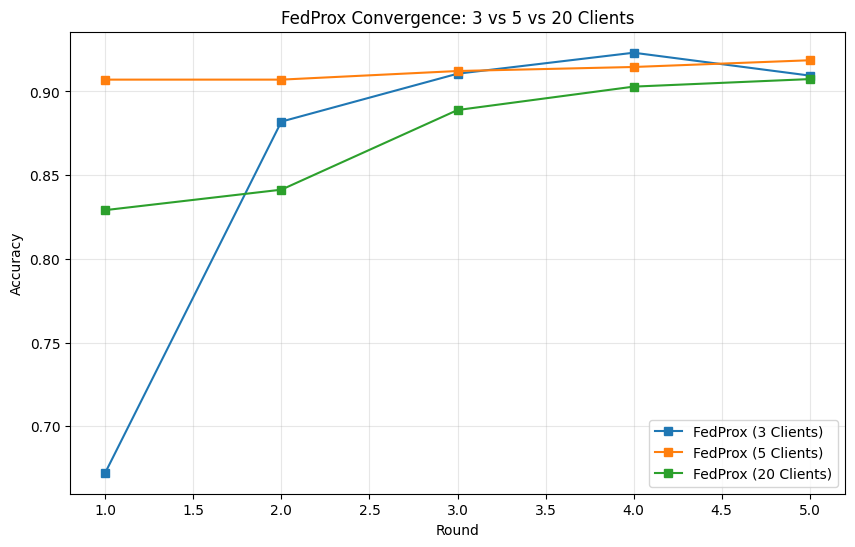


Clients    | Accuracy   | Precision  | Recall     | F1-Score  
----------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


3          | 0.9075     | 0.9076     | 0.9075     | 0.9075    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


5          | 0.9138     | 0.9169     | 0.9138     | 0.9136    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


20         | 0.9030     | 0.9106     | 0.9030     | 0.9026    


In [ ]:
plt.figure(figsize=(10, 6))
for n_clients, data in fedprox_results.items():
    plt.plot(range(1, num_rounds + 1), data['accuracies'], marker='s', label=f'FedProx ({n_clients} Clients)')
plt.title("FedProx Convergence: 3 vs 5 vs 20 Clients")
plt.xlabel("Round")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"\n{'Clients':<10} | {'Accuracy':<10} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 70)

for n_clients in experiment_client_counts:
    eval_model = get_model()
    eval_model.load_state_dict(fedprox_results[n_clients]['final_weights'])
    y_true, y_pred, y_probs = evaluate_model_full(eval_model, test_loader)

    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')

    print(f"{n_clients:<10} | {acc:<10.4f} | {prec:<10.4f} | {rec:<10.4f} | {f1:<10.4f}")

load model and compute comparison ROC

Extracting dataset...
Dataset extracted successfully.
Removing __MACOSX directory...
__MACOSX directory removed.
Test dataset loaded with 6216 images.
Processed FedAvg - AUC: 0.9464
Processed FedProx - AUC: 0.9158
Processed FedNova - AUC: 0.6060
Processed W-FedAvg (Proposed) - AUC: 0.9277


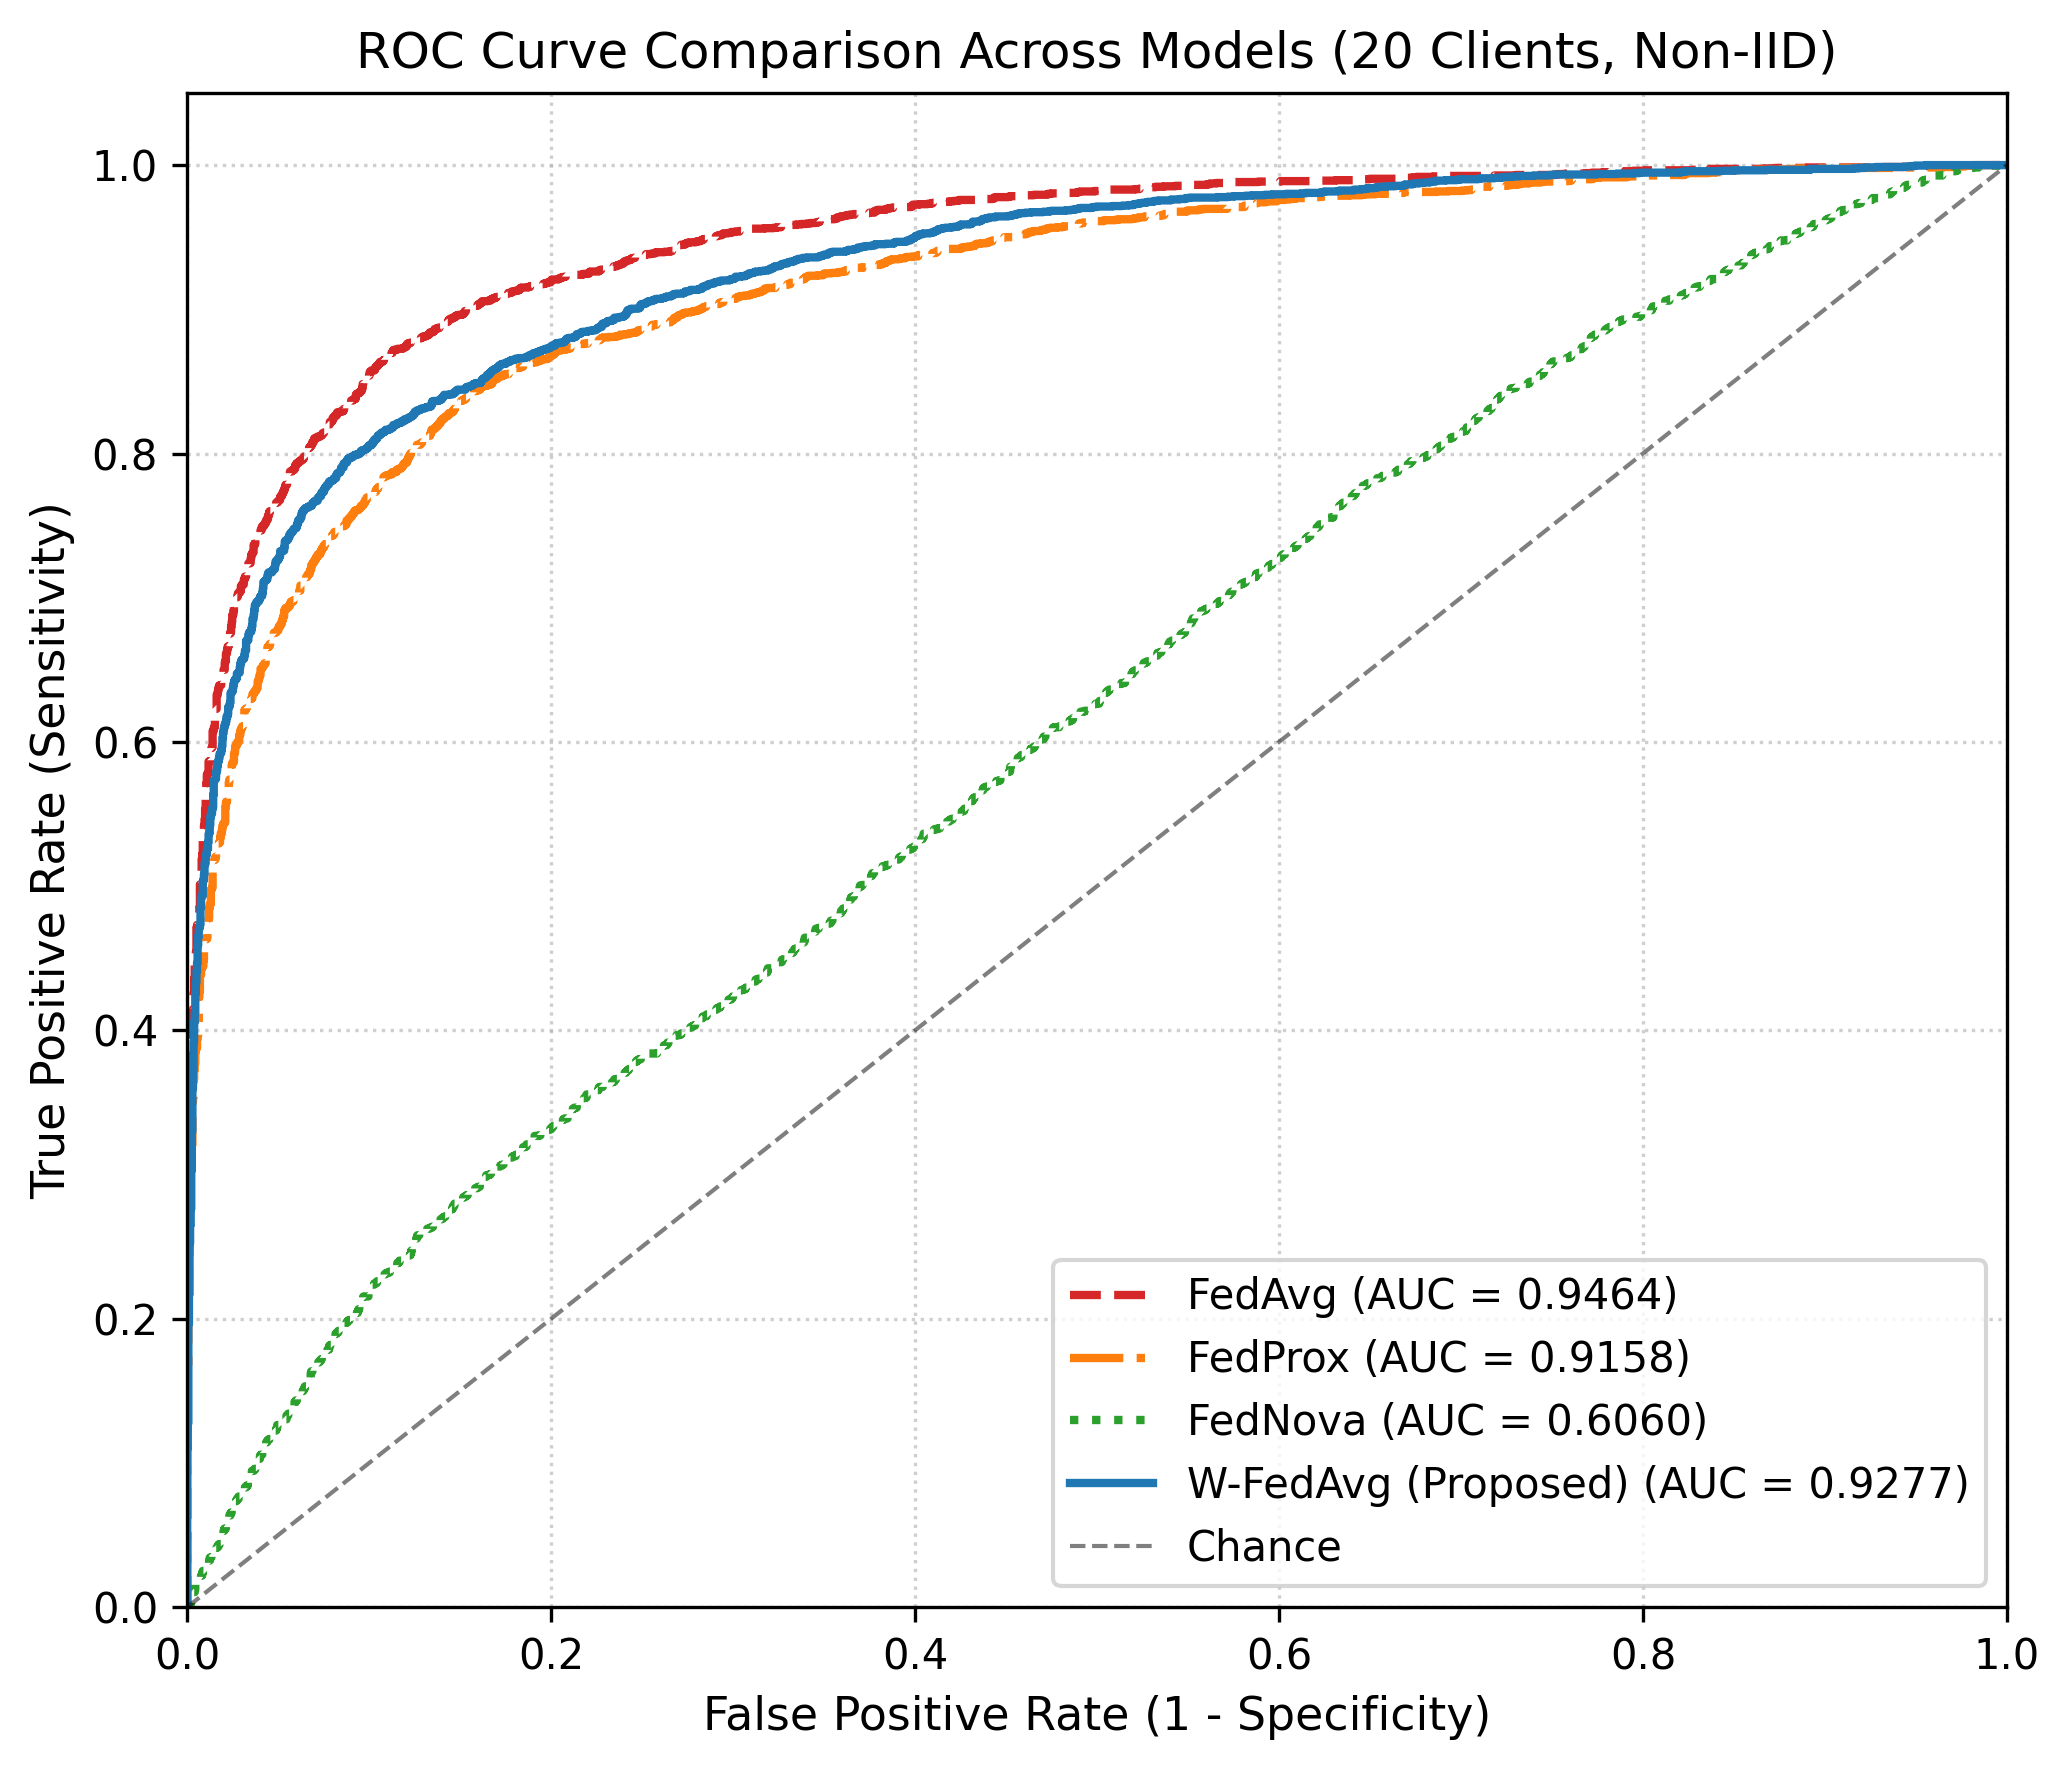

ROC curve figure successfully saved to /tmp/roc_curve_comparison.png


In [ ]:
import os
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import auc, roc_curve
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
import shutil  # Import shutil for directory removal
from PIL import ImageFile # Explicitly import ImageFile

# -------------------------------------------------------------
# 1. UNZIP DATASET
# -------------------------------------------------------------
zip_path = '/content/drive/MyDrive/dataset/dataset.zip'
extract_path = '/content/extracted_dataset'

# Remove extract_path if it exists to ensure a clean extraction
if os.path.exists(extract_path):
  shutil.rmtree(extract_path)
os.makedirs(extract_path, exist_ok=True)

if os.path.exists(zip_path):
  print('Extracting dataset...')
  with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
  print('Dataset extracted successfully.')

  # Remove __MACOSX directory if it exists (contains metadata, not actual images)
  macosx_path = os.path.join(extract_path, '__MACOSX')
  if os.path.exists(macosx_path):
    print('Removing __MACOSX directory...')
    shutil.rmtree(macosx_path)
    print('__MACOSX directory removed.')

else:
  print(f'Warning: Zip file not found at {zip_path}')

# Define test directory path (adjust subfolder if needed, e.g., 'test' or 'val')
TEST_DATA_DIR = os.path.join(extract_path, 'dataset/test1') # Adjusted to point directly to the images
if not os.path.exists(TEST_DATA_DIR):
  # Fallback to root extracted folder if no 'test' subfolder exists
  TEST_DATA_DIR = extract_path

# -------------------------------------------------------------
# 2. SETTINGS & MODEL PATHS
# -------------------------------------------------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model_paths = {
    'FedAvg': '/content/drive/MyDrive/fedavg_20_clients.pth',
    'FedProx': '/content/drive/MyDrive/fedprox_20_clients.pth',
    'FedNova': '/content/drive/MyDrive/fednova_20_clients.pth',
    'W-FedAvg (Proposed)': '/content/drive/MyDrive/cbp_fedavg_20_clients.pth',
}

# Initialize save_path for the plot
save_path = '/tmp/roc_curve_comparison.png'

# -------------------------------------------------------------
# 3. CREATE TEST LOADER
# -------------------------------------------------------------
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
    ),
])

test_dataset = datasets.ImageFolder(
    root=TEST_DATA_DIR, transform=test_transform
)

# Define a worker initialization function for DataLoader
def worker_init_fn(worker_id):
    ImageFile.LOAD_TRUNCATED_IMAGES = True
    ImageFile.MAX_IMAGE_PIXELS = None

test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=2, worker_init_fn=worker_init_fn
)
print(f'Test dataset loaded with {len(test_dataset)} images.')


# -------------------------------------------------------------
# 4. HELPER FUNCTIONS
# -------------------------------------------------------------
def load_resnet18_model(model_path, num_classes=2):
  model = models.resnet18(weights=None)
  model.fc = nn.Linear(model.fc.in_features, num_classes)

  state_dict = torch.load(model_path, map_location=device)
  model.load_state_dict(state_dict)
  model.to(device)
  model.eval()
  return model


def get_predictions_and_labels(model, loader):
  all_probs = []
  all_labels = []

  with torch.no_grad():
    for inputs, labels in loader:
      inputs = inputs.to(device)
      outputs = model(inputs)
      probs = torch.softmax(outputs, dim=1)[:, 1]

      all_probs.extend(probs.cpu().numpy())
      all_labels.extend(labels.numpy())

  return np.array(all_labels), np.array(all_probs)


# -------------------------------------------------------------
# 5. GENERATE ROC PLOT
# -------------------------------------------------------------
plt.figure(figsize=(7, 6), dpi=300)

colors = {
    'FedAvg': '#d62728',
    'FedProx': '#ff7f0e',
    'FedNova': '#2ca02c',
    'W-FedAvg (Proposed)': '#1f77b4',
}

linestyles = {
    'FedAvg': '--',
    'FedProx': '-.',
    'FedNova': ':',
    'W-FedAvg (Proposed)': '-',
}

for name, path in model_paths.items():
  if os.path.exists(path):
    try:
      model = load_resnet18_model(path)
      y_true, y_probs = get_predictions_and_labels(model, test_loader)

      fpr, tpr, _ = roc_curve(y_true, y_probs)
      roc_auc = auc(fpr, tpr)

      plt.plot(
          fpr,
          tpr,
          label=f'{name} (AUC = {roc_auc:.4f})',
          color=colors[name],
          linestyle=linestyles[name],
          linewidth=2,
      )
      print(f'Processed {name} - AUC: {roc_auc:.4f}')
    except Exception as e:
      print(f'Error evaluating {name}: {e}')
  else:
    print(f'File not found: {path}')

plt.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=11)
plt.title(
    'ROC Curve Comparison Across Models (20 Clients, Non-IID)', fontsize=12
)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save output image
plt.savefig(save_path, dpi=300)
plt.show()
print(f'ROC curve figure successfully saved to {save_path}')

Evaluating on path: /content/extracted_dataset/dataset/test1 | Class mapping: {'1': 0, '2': 1}

Model                  | AUC      | Accuracy   | Precision  | Recall     | F1-Score  
--------------------------------------------------------------------------------


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


FedAvg                 | 0.9796   | 0.9299     | 0.9302     | 0.9299     | 0.9298    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


FedProx                | 0.9820   | 0.9030     | 0.9106     | 0.9030     | 0.9026    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


FedNova                | 0.9696   | 0.8949     | 0.8990     | 0.8949     | 0.8948    


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


W-FedAvg (Proposed)    | 0.9828   | 0.9054     | 0.9133     | 0.9054     | 0.9051    


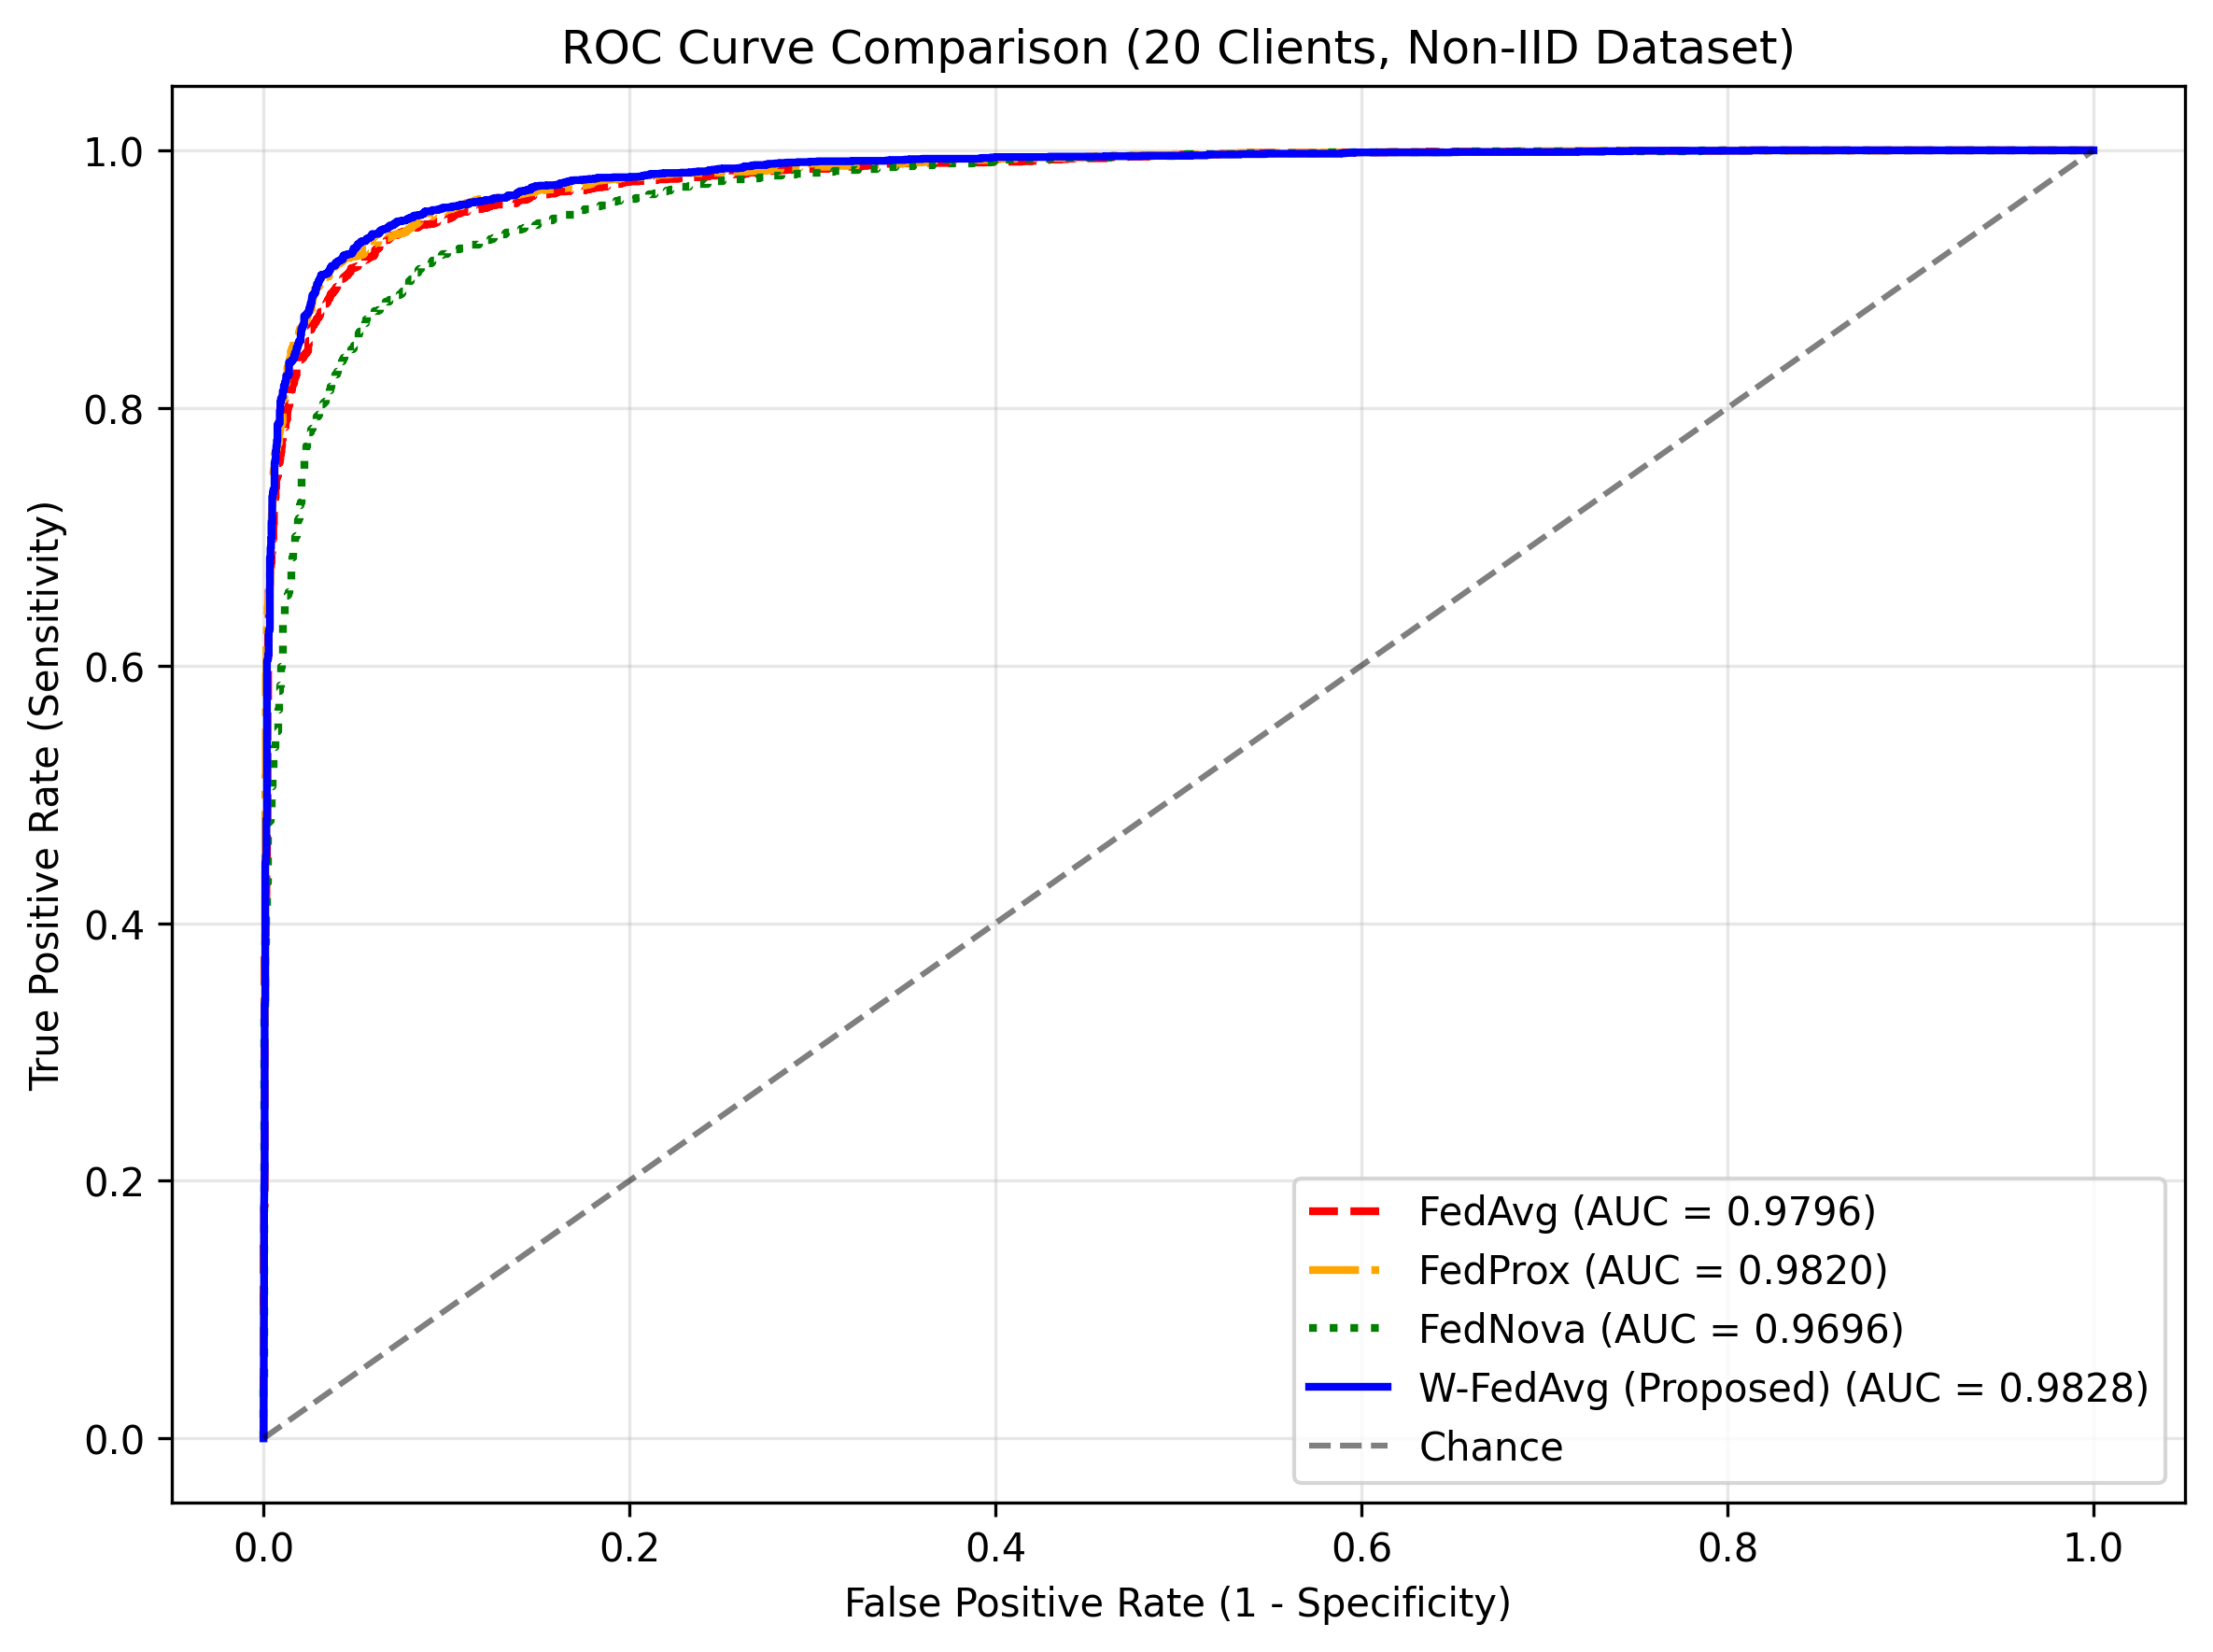

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import auc, precision_recall_fscore_support, roc_curve
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from PIL import ImageFile # Import ImageFile

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Match Exact Data Folder & Transform from your Notebook Block 2
dataset_root = '/content/extracted_dataset/dataset'
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Ensure using 'test1' matching your original code
test_path = (
    os.path.join(dataset_root, 'test1')
    if os.path.exists(os.path.join(dataset_root, 'test1'))
    else os.path.join(dataset_root, 'test')
)
test_dataset = datasets.ImageFolder(root=test_path, transform=transform)

# Define a worker initialization function for DataLoader
def worker_init_fn(worker_id):
    ImageFile.LOAD_TRUNCATED_IMAGES = True
    ImageFile.MAX_IMAGE_PIXELS = None

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, worker_init_fn=worker_init_fn)

print(
    f'Evaluating on path: {test_path} | Class mapping: {test_dataset.class_to_idx}'
)


def get_model():
  model = models.resnet18(pretrained=False)
  model.fc = nn.Linear(model.fc.in_features, 2)
  return model.to(device)


def evaluate_model_full(model, loader):
  model.eval()
  all_preds, all_labels, all_probs = [], [], []
  with torch.no_grad():
    for images, labels in loader:
      images, labels = images.to(device), labels.to(device)
      outputs = model(images)
      probs = torch.softmax(outputs, dim=1)
      _, preds = torch.max(outputs, 1)

      all_preds.extend(preds.cpu().numpy())
      all_labels.extend(labels.cpu().numpy())
      all_probs.extend(probs[:, 1].cpu().numpy())
  return np.array(all_labels), np.array(all_preds), np.array(all_probs)


# 2. Checkpoints mapping (20 clients comparison)
model_files = {
    'FedAvg': '/content/drive/MyDrive/fedavg_20_clients.pth',
    'FedProx': '/content/drive/MyDrive/fedprox_20_clients.pth',
    'FedNova': '/content/drive/MyDrive/fednova_20_clients.pth',
    'W-FedAvg (Proposed)': '/content/drive/MyDrive/cbp_fedavg_20_clients.pth',
}

plt.figure(figsize=(8, 6), dpi=300)
print(
    f"\n{'Model':<22} | {'AUC':<8} | {'Accuracy':<10} | {'Precision':<10} |"
    f" {'Recall':<10} | {'F1-Score':<10}"
)
print('-' * 80)

colors = {
    'FedAvg': 'red',
    'FedProx': 'orange',
    'FedNova': 'green',
    'W-FedAvg (Proposed)': 'blue',
}
styles = {
    'FedAvg': '--',
    'FedProx': '-.',
    'FedNova': ':',
    'W-FedAvg (Proposed)': '-',
}

for name, path in model_files.items():
  if not os.path.exists(path):
    print(f'Missing checkpoint: {path}')
    continue

  model = get_model()
  model.load_state_dict(torch.load(path, map_location=device))

  y_true, y_pred, y_probs = evaluate_model_full(model, test_loader)

  # Recalculate metrics
  acc = np.mean(y_true == y_pred)
  prec, rec, f1, _ = precision_recall_fscore_support(
      y_true, y_pred, average='weighted'
  )
  fpr, tpr, _ = roc_curve(y_true, y_probs)
  roc_auc = auc(fpr, tpr)

  print(
      f'{name:<22} | {roc_auc:<8.4f} | {acc:<10.4f} | {prec:<10.4f} |'
      f' {rec:<10.4f} | {f1:<10.4f}'
  )

  plt.plot(
      fpr,
      tpr,
      color=colors[name],
      linestyle=styles[name],
      linewidth=2,
      label=f'{name} (AUC = {roc_auc:.4f})',
  )

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Chance')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve Comparison (20 Clients, Non-IID Dataset)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/roc_comparison_corrected.png', dpi=300)
plt.show()